Ciarra R.Barnett

In [4]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [5]:
framingham = pd.read_csv("data/framingham.csv")
 
print(framingham.isna().sum())
print(framingham.shape)
 

missing_framingham = framingham.copy()
missing_framingham.loc[missing_framingham.sample(frac=0.8, random_state=567).index, 'sysBP'] = np.nan
 
print("Missing sysBP values:", missing_framingham['sysBP'].isna().sum())
 


male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64
(4240, 16)
Missing sysBP values: 3392


In [3]:
observed = missing_framingham[missing_framingham['sysBP'].notna()]
missing = missing_framingham[missing_framingham['sysBP'].isna()]
 
formula = "sysBP ~ age + cigsPerDay + BMI"
imputer_model = smf.ols(formula, data=observed).fit()
 
predicted = imputer_model.predict(missing)
residual_std = np.std(imputer_model.resid)
 
# %%
# 1a: run Approach #4 with the ORIGINAL noise seed (123) and a NEW noise seed (456).
# Each seed imputes into its own copy, so missing_framingham keeps its missing values.
final_formula = "totChol ~ age + cigsPerDay + sysBP + BMI"
 
seed_models = {}
for noise_seed in [123, 456]:
    rng = np.random.default_rng(noise_seed)
    imputed_values = predicted + rng.normal(0, residual_std, size=len(predicted))
 
    seed_data = missing_framingham.copy()
    seed_data.loc[missing.index, 'sysBP'] = imputed_values
 
    seed_models[noise_seed] = smf.ols(final_formula, data=seed_data).fit()
 
for noise_seed, m in seed_models.items():
    print(f"Noise seed {noise_seed}: sysBP coefficient = {m.params['sysBP']:.4f}")
 
print("Difference:", seed_models[456].params['sysBP'] - seed_models[123].params['sysBP'])

Noise seed 123: sysBP coefficient = 0.0157
Noise seed 456: sysBP coefficient = 0.0249
Difference: 0.009146979883753938


1a. Yes, the sysBP coefficient changes: it is 0.0157 with seed 123 and 0.0249 with seed 456. The only thing that changed between the two runs was the random noise added to the imputed values. The same sysBP values were missing both times, and the models were the same. So the change comes from the imputation itself, not from the data.

In [ ]:
 ## 1b. 
formula = "sysBP ~ age + cigsPerDay + BMI"
imputer_model = smf.ols(formula, data=observed).fit()
 
formula2 = "sysBP ~ age + cigsPerDay + BMI + totChol"
imputer_model2 = smf.ols(formula2, data=observed).fit()
 
print(imputer_model.params.round(4), "\n")
print(imputer_model2.params.round(4))

Intercept     43.8894
age            0.8551
cigsPerDay     0.0458
BMI            1.8221
dtype: float64 

Intercept     41.1381
age            0.8013
cigsPerDay     0.0528
BMI            1.7687
totChol        0.0287
dtype: float64


In [7]:
regression_framingham = missing_framingham.copy()
target_framingham = missing_framingham.copy()
 
noise_seed = 456
 
predicted = imputer_model.predict(missing).dropna()
residual_std = np.std(imputer_model.resid)
rng = np.random.default_rng(noise_seed)
 
imputed_values = predicted + rng.normal(0, residual_std, size=len(predicted))
regression_framingham.loc[predicted.index, 'sysBP'] = imputed_values
 
predicted2 = imputer_model2.predict(missing).dropna()
residual_std2 = np.std(imputer_model2.resid)
rng2 = np.random.default_rng(noise_seed)
 
imputed_values2 = predicted2 + rng2.normal(0, residual_std2, size=len(predicted2))
target_framingham.loc[predicted2.index, 'sysBP'] = imputed_values2
 
print("Originally missing:", len(missing))
print("Model 4 missing:", regression_framingham['sysBP'].isna().sum())
print("Model 5 missing:", target_framingham['sysBP'].isna().sum())

Originally missing: 3392
Model 4 missing: 38
Model 5 missing: 78


In [8]:
model1 = smf.ols(final_formula, data=framingham).fit()
 
model2 = smf.ols(final_formula, data=missing_framingham).fit()
 
mean_framingham = missing_framingham.copy()
mean_framingham['sysBP'] = mean_framingham['sysBP'].fillna(
    mean_framingham['sysBP'].mean()
)
model3 = smf.ols(final_formula, data=mean_framingham).fit()
 
model4 = smf.ols(final_formula, data=regression_framingham).fit()
model5 = smf.ols(final_formula, data=target_framingham).fit()
 
models = {"Full Model": model1, "Missing Data": model2, "Mean Imputation": model3,
          "Regression Imputation": model4, "Regression with Target": model5}
 
comparison = pd.DataFrame({
    label: pd.concat([
        m.params,
        pd.Series({"R2": m.rsquared, "Rows used": m.nobs})
    ])
    for label, m in models.items()
})
 
formatted = comparison.map("{:.4f}".format)
formatted.loc["Rows used"] = comparison.loc["Rows used"].map("{:,.0f}".format)
 
display(formatted)
 
print("Model 4 sysBP coefficient:", model4.params['sysBP'])
print("Model 5 sysBP coefficient:", model5.params['sysBP'])
print("Difference:", model5.params['sysBP'] - model4.params['sysBP'])

,Full Model,Missing Data,Mean Imputation,Regression Imputation,Regression with Target
Intercept,134.2330,117.2945,125.2827,143.1261,135.5965
age,1.1522,1.3827,1.3259,1.3223,1.2019
cigsPerDay,0.1115,0.1058,0.1121,0.1129,0.1040
sysBP,0.2207,0.1423,0.1685,0.0379,0.1828
BMI,0.5886,1.1139,0.8588,0.8521,0.6280
R2,0.0871,0.1042,0.0793,0.0782,0.0842
Rows used,"4,143",829,"4,143","4,143","4,143"


Model 4 sysBP coefficient: 0.037900553727836704
Model 5 sysBP coefficient: 0.18281354523764357
Difference: 0.14491299150980685


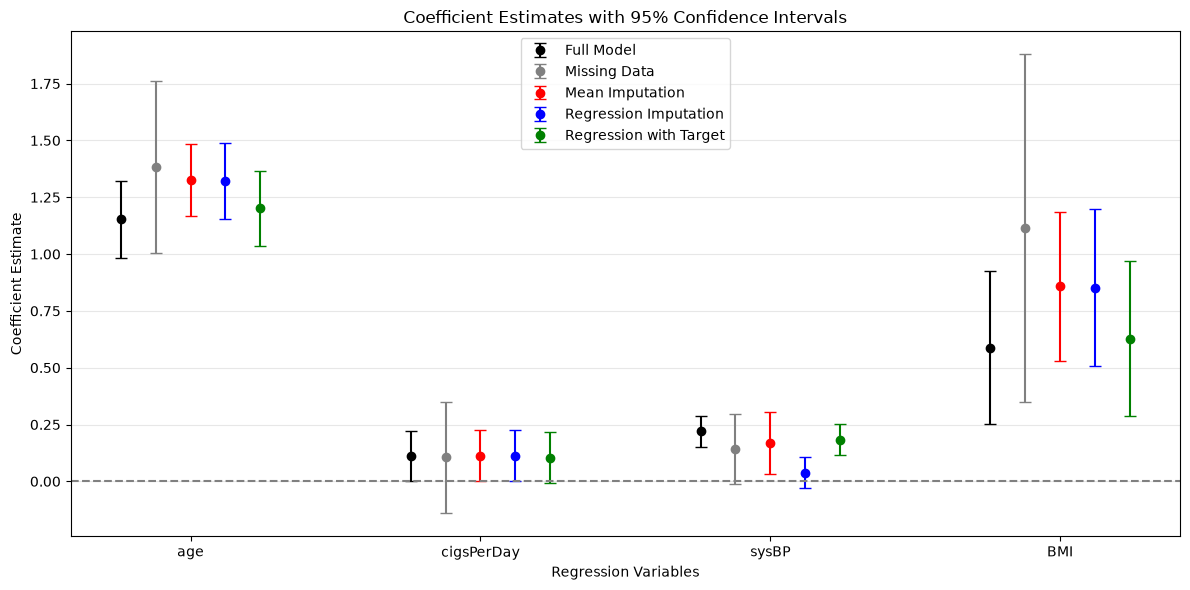

In [9]:
models = {
    "Full Model": (model1, "black"),
    "Missing Data": (model2, "gray"),
    "Mean Imputation": (model3, "red"),
    "Regression Imputation": (model4, "blue"),
    "Regression with Target": (model5, "green")
}
 
tables = {}
for name, (model, color) in models.items():
    ci = model.conf_int()
    tables[name] = pd.DataFrame({
        "coef": model.params,
        "lower": ci[0],
        "upper": ci[1]
    })
 
common_vars = tables["Full Model"].index
for t in tables.values():
    common_vars = common_vars.intersection(t.index)
common_vars = common_vars.drop("Intercept")   
 
x = np.arange(len(common_vars))
width = 0.6 / len(models)
offsets = (np.arange(len(models)) - (len(models) - 1) / 2) * width
 
plt.figure(figsize=(12, 6))
for offset, (name, (model, color)) in zip(offsets, models.items()):
    t = tables[name].loc[common_vars]
    plt.errorbar(
        x + offset,
        t["coef"],
        yerr=[t["coef"] - t["lower"], t["upper"] - t["coef"]],
        fmt="o",
        color=color,
        ecolor=color,
        capsize=4,
        label=name
    )
 
plt.axhline(0, color="gray", linestyle="--")
plt.xticks(x, common_vars)
plt.ylabel("Coefficient Estimate")
plt.xlabel("Regression Variables")
plt.title("Coefficient Estimates with 95% Confidence Intervals")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

1c. Including totChol in the imputer gave a sysBP coefficient of 0.1828, much closer to the full-data value of 0.2207 than the first regression imputation’s 0.0379, whose confidence interval even included 0. The first imputer filled in sysBP values with no connection to totChol, and since about 80% of sysBP was imputed, this pulled the relationship toward zero. Including the target keeps that relationship in the imputed values, and it isn’t cheating because we only use totChol to fill in a missing predictor, not to predict totChol itself.

## Part 2. 


In [13]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import log_loss, accuracy_score, precision_score, recall_score, ConfusionMatrixDisplay, confusion_matrix

In [14]:
warnings.filterwarnings("ignore")   
 
col_names = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe", "type"]
glass = pd.read_csv("data/glass.csv", header=None, names=col_names)
 
class_names = {1: "building_float", 2: "building_nonfloat", 3: "vehicle_float",
               5: "containers", 6: "tableware", 7: "headlamps"}
features = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]
 
X = glass[features]
y = glass["type"]
 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=113
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=224)

In [15]:
print(glass.shape)
print(f"Training set: {X_train.shape}  |  Test set: {X_test.shape}")
labels = sorted(class_names)                      
label_names = [class_names[k] for k in labels]
glass.head()

(214, 10)
Training set: (171, 9)  |  Test set: (43, 9)


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,type
1,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
2,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
3,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
4,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
5,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


In [16]:
def cv_scores(model):
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=["neg_log_loss", "accuracy"])
    return {
        "log loss (mean)": -res["test_neg_log_loss"].mean(),
        "log loss (sd)": res["test_neg_log_loss"].std(),
        "accuracy (mean)": res["test_accuracy"].mean(),
        "accuracy (sd)": res["test_accuracy"].std(),
    }
 
def cv_pred(model):
    return cross_val_predict(model, X_train, y_train, cv=cv)

In [17]:
X.describe().T[["mean", "std", "min", "max"]].round(3)

,mean,std,min,max
RI,1.518,0.003,1.511,1.534
Na,13.408,0.817,10.730,17.380
Mg,2.685,1.442,0.000,4.490
Al,1.445,0.499,0.290,3.500
Si,72.651,0.775,69.810,75.410
K,0.497,0.652,0.000,6.210
Ca,8.957,1.423,5.430,16.190
Ba,0.175,0.497,0.000,3.150
Fe,0.057,0.097,0.000,0.510


1a. The table shows the mean, standard deviation, min, and max for each feature. The features are on very different scales. Si has a mean of about 72.65, while Fe, Ba, and K are mostly close to 0 (Fe has a max of only 0.51). RI barely varies (SD of 0.003), while Mg and Ca have SDs around 1.4. 

In [18]:
class_counts = pd.DataFrame({
    "train": y_train.value_counts(),
    "test": y_test.value_counts(),
}).sort_index()
class_counts["total"] = class_counts["train"] + class_counts["test"]
class_counts["train %"] = (100 * class_counts["train"] / class_counts["train"].sum()).round(1)
class_counts.index = [f"{k}: {class_names[k]}" for k in class_counts.index]
class_counts.loc["Total"] = class_counts.sum(numeric_only=True)
class_counts.loc["Total", "train %"] = 100.0
class_counts.astype({"train": int, "test": int, "total": int})

,train,test,total,train %
1: building_float,56,14,70,32.7
2: building_nonfloat,61,15,76,35.7
3: vehicle_float,14,3,17,8.2
5: containers,10,3,13,5.8
6: tableware,7,2,9,4.1
7: headlamps,23,6,29,13.5
Total,171,43,214,100.0


1b. The rare classes are tableware (7 train / 2 test), containers (10 train / 3 test), and vehicle_float (14 train / 3 test), which each make up less than 10% of the training set. The most common class is building_nonfloat (61 train / 15 test, 35.7% of training), followed closely by building_float (56 train / 14 test, 32.7%).

In [19]:
most_common = y_train.value_counts().idxmax()
acc_majority = accuracy_score(y_train, np.full(len(y_train), most_common))
print(f"Most common class: {most_common} ({class_names[most_common]})")
print(f"Majority-class accuracy on the training set: {acc_majority:.4f}")

Most common class: 2 (building_nonfloat)
Majority-class accuracy on the training set: 0.3567


1c. A model that always predicts the most common class  building_nonfloat has a training accuracy of 0.3567, since 61 of the 171 training fragments are building_nonfloat.

In [20]:
class_props = y_train.value_counts(normalize=True).sort_index().values
ll_base = log_loss(y_train, np.tile(class_props, (len(y_train), 1)))
print("Training class proportions:", {k: round(float(v), 4) for k, v in zip(label_names, class_props)})
print(f"Base-rate log loss: {ll_base:.4f}")
 
y_ll = pd.get_dummies(y_train).sort_index(axis=1).values
p_ll = np.tile(class_props, (len(y_train), 1))
ll_by_hand = -np.mean(np.sum(y_ll * np.log(p_ll), axis=1))
print(f"Base-rate log loss (by hand): {ll_by_hand:.4f}")

Training class proportions: {'building_float': 0.3275, 'building_nonfloat': 0.3567, 'vehicle_float': 0.0819, 'containers': 0.0585, 'tableware': 0.0409, 'headlamps': 0.1345}
Base-rate log loss: 1.5049
Base-rate log loss (by hand): 1.5049


1d. Predicting the training class proportions for every fragment gives a base-rate log loss of 1.5049. I calculated it with sklearn's log_loss and by hand, and both give the same value.

In [21]:
K = len(labels)
print(f"K = {K},  ln K = ln {K} = {np.log(K):.4f}")
print(f"Base-rate log loss = {ll_base:.4f}")
print(f"Log loss predicting 1/K for every class: {log_loss(y_train, np.full((len(y_train), K), 1/K)):.4f}")

K = 6,  ln K = ln 6 = 1.7918
Base-rate log loss = 1.5049
Log loss predicting 1/K for every class: 1.7918


1e. Giving all six classes the same probability results in a log loss of 1.7918. However, some classes appear more often than others. The base-rate model gives higher probabilities to common classes, which lowers the log loss to 1.5049 and improves predictions.

count    214.0000
mean      99.8743
std        0.1221
min       99.0200
25%       99.8100
50%       99.8900
75%       99.9600
max      100.1000
dtype: float64


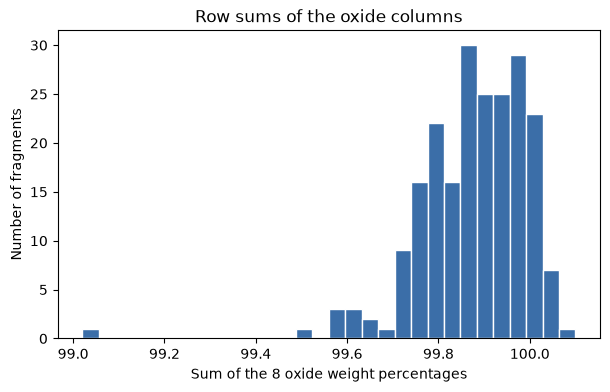

In [ ]:
 # 2a
oxides = [f for f in features if f != "RI"]
oxide_sum = glass[oxides].sum(axis=1)
print(oxide_sum.describe().round(4))
 
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(oxide_sum, bins=30, color="#3b6ea8", edgecolor="white")
ax.set(xlabel="Sum of the 8 oxide weight percentages", ylabel="Number of fragments",
       title="Row sums of the oxide columns")
plt.show()


2a. The eight oxide columns add up to nearly 100%, with an average of 99.87, a standard deviation of 0.12, and values between 99.02 and 100.10. This makes sense because they represent the glass composition. Since they total almost 100%, knowing seven values allows us to estimate the eighth.

In [27]:
display(pd.Series(unpen_scores).round(4))
...
display(coef_unpen.round(2))

log loss (mean)    4.2544
log loss (sd)      1.0127
accuracy (mean)    0.6262
accuracy (sd)      0.0745
dtype: float64

,building_float,building_nonfloat,vehicle_float,containers,tableware,headlamps
RI,-12.99,-11.74,-18.40,-12.10,22.68,32.54
Na,-23.72,-28.47,-17.42,-22.52,43.74,48.39
Mg,-5.78,-17.39,6.24,-11.31,11.53,16.72
Al,-14.65,-15.20,-10.37,-5.71,25.39,20.54
Si,-17.41,-22.34,-13.88,-14.05,25.57,42.12
K,3.30,-0.32,5.91,2.52,-39.09,27.68
Ca,-0.90,-11.34,14.74,-0.25,-6.36,4.10
Ba,3.55,-0.87,6.29,2.85,-32.11,20.28
Fe,13.64,13.88,13.26,13.42,-39.67,-14.54


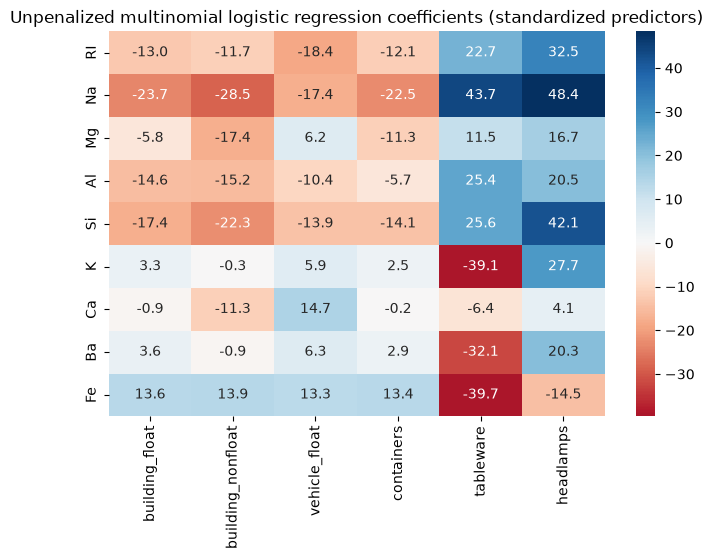

In [23]:
## 2b. 

model_unpen = Pipeline(steps=[("scale", StandardScaler()),("model", LogisticRegression(C=np.inf, max_iter=50000)),])
 
unpen_scores = cv_scores(model_unpen)
pd.Series(unpen_scores).round(4)
 
model_unpen.fit(X_train, y_train)
coef_unpen = pd.DataFrame(model_unpen.named_steps["model"].coef_.T,
                          index=features, columns=label_names)
coef_unpen.round(2)
 
plt.figure(figsize=(8, 5))
sns.heatmap(coef_unpen, annot=True, fmt=".1f", cmap="RdBu", center=0)
plt.title("Unpenalized multinomial logistic regression coefficients (standardized predictors)")
plt.show()

2b. The logistic regression model has an average CV accuracy of 0.6262, which is better than the baseline of 0.3567. However, its log loss is very high at 4.2544 (SD 1.0127), showing poor probability predictions. Some coefficients are also pretty large, such as Na (48.4) and Fe (−39.7), even after standardization. This suggests the model may be overfitting the data

In [24]:
def vif_table(df):
    out = {}
    for col in df.columns:
        others = df.drop(columns=col)
        r2 = LinearRegression().fit(others, df[col]).score(others, df[col])
        out[col] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(out, name="VIF")
 
vif = vif_table(X_train)
vif.round(1).to_frame()

,VIF
RI,11.5
Na,90.5
Mg,291.9
Al,33.9
Si,83.4
K,45.4
Ca,335.0
Ba,38.5
Fe,1.4


2c. Most predictors have very high VIF values, especially Ca (335.0) and Mg (291.9), while Fe (1.4) is low. This shows severe multicollinearity because the oxides add up to nearly 100% and are closely related. As a result, the model struggles to separate their individual effects, causing large, unstable coefficients that are difficult to interpret.

In [25]:
print(f"Base-rate log loss (no predictors): {ll_base:.4f}")
print(f"Unpenalized model CV log loss:      {unpen_scores['log loss (mean)']:.4f}  (sd {unpen_scores['log loss (sd)']:.4f})")
print(f"Unpenalized model CV accuracy:      {unpen_scores['accuracy (mean)']:.4f}")
print(f"Majority-class accuracy:            {acc_majority:.4f}")
 

proba_unpen = cross_val_predict(model_unpen, X_train, y_train, cv=cv, method="predict_proba")
true_idx = np.searchsorted(labels, y_train.values)
p_true_unpen = proba_unpen[np.arange(len(y_train)), true_idx]
eps = np.finfo(float).eps
loss_i = -np.log(np.clip(p_true_unpen, eps, 1))
 
print(f"Pooled out-of-fold log loss: {loss_i.mean():.4f}")
print(f"Fragments with P(true class) < 0.01: {(p_true_unpen < 0.01).sum()} of {len(p_true_unpen)}")
top = np.sort(loss_i)[::-1]
print(f"Share of total log loss from the 10 worst fragments: {top[:10].sum() / loss_i.sum():.1%}")
pd.DataFrame({"true class": y_train.map(class_names).values,
              "P(true class)": p_true_unpen,
              "log loss contribution": loss_i}).sort_values("log loss contribution", ascending=False).head(10).round(6)

Base-rate log loss (no predictors): 1.5049
Unpenalized model CV log loss:      4.2544  (sd 1.0127)
Unpenalized model CV accuracy:      0.6262
Majority-class accuracy:            0.3567
Pooled out-of-fold log loss: 4.2655
Fragments with P(true class) < 0.01: 24 of 171
Share of total log loss from the 10 worst fragments: 49.4%


,true class,P(true class),log loss contribution
17,headlamps,0.0,36.043653
88,containers,0.0,36.043653
2,building_nonfloat,0.0,36.043653
51,headlamps,0.0,36.043653
139,building_nonfloat,0.0,36.043653
62,containers,0.0,36.043653
22,containers,0.0,36.043653
135,building_nonfloat,0.0,36.043653
111,building_float,0.0,36.043653
126,headlamps,0.0,36.043653


2d. The model has better accuracy (62.6%) than the baseline (35.7%), but its log loss is much worse (4.2544 vs. 1.5049). This happens because the model makes very confident predictions, even when it is wrong. In my results, 24 out of 171 fragments received very low probabilities for their correct class, and the 10 worst predictions caused 49.4% of the total log loss. This shows that a few highly confident mistakes can greatly increase log loss, even when accuracy is good.

In [35]:
 ## 3. 
def make_model(C, l1_ratio):
    return Pipeline(steps=[
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=C, l1_ratio=l1_ratio, solver="saga", max_iter=50000, random_state=48)),
    ])
 
C_values = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000]
l1_ratios = {"lasso": 1, "enet 0.75": 0.75, "enet 0.5": 0.5, "enet 0.25": 0.25, "ridge": 0}
 
all_results = pd.DataFrame([{"model": name, "C": C, **cv_scores(make_model(C, r))}
                            for name, r in l1_ratios.items() for C in C_values])

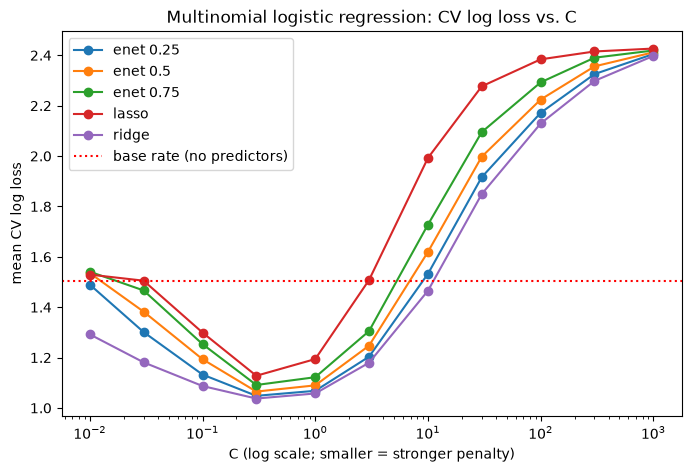

In [29]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, g in all_results.groupby("model"):
    ax.plot(g["C"], g["log loss (mean)"], marker="o", label=name)
ax.axhline(ll_base, color="red", ls=":", label="base rate (no predictors)")
ax.set(xscale="log", xlabel="C (log scale; smaller = stronger penalty)",
       ylabel="mean CV log loss", title="Multinomial logistic regression: CV log loss vs. C")
ax.legend()
plt.show()

In [30]:
best = all_results.loc[all_results["log loss (mean)"].idxmin()]
print(f"Lowest CV log loss: {best['model']}, C = {best['C']}, "
      f"log loss = {best['log loss (mean)']:.4f}, accuracy = {best['accuracy (mean)']:.4f}")
 
cutoff = best["log loss (mean)"] + best["log loss (sd)"] / np.sqrt(5)
print(f"One-SE cutoff: {cutoff:.4f}")
 
candidates = all_results[all_results["log loss (mean)"] <= cutoff].copy()
candidates["l1_ratio"] = candidates["model"].map(l1_ratios)
 
candidates["nonzero coefs (of 54)"] = [
    int((make_model(C, r).fit(X_train, y_train).named_steps["model"].coef_ != 0).sum())
    for C, r in zip(candidates["C"], candidates["l1_ratio"])
]
simplest = candidates.sort_values(["nonzero coefs (of 54)", "C"]).iloc[0]   # fewest nonzero, then smallest C
 
C_best, method_best, l1_best = simplest["C"], simplest["model"], simplest["l1_ratio"]
print(f"Simplest within 1 SE: {method_best} (l1_ratio = {l1_best}), C = {C_best}, "
      f"nonzero coefficients = {simplest['nonzero coefs (of 54)']} of 54")
print(f"  CV log loss = {simplest['log loss (mean)']:.4f}, CV accuracy = {simplest['accuracy (mean)']:.4f}")
model_best = make_model(C_best, l1_best)
candidates.round(4)

Lowest CV log loss: ridge, C = 0.3, log loss = 1.0374, accuracy = 0.5971
One-SE cutoff: 1.1072
Simplest within 1 SE: enet 0.75 (l1_ratio = 0.75), C = 0.3, nonzero coefficients = 27 of 54
  CV log loss = 1.0912, CV accuracy = 0.5854


,model,C,log loss (mean),log loss (sd),accuracy (mean),accuracy (sd),l1_ratio,nonzero coefs (of 54)
14,enet 0.75,0.3,1.0912,0.1711,0.5854,0.0575,0.75,27
25,enet 0.5,0.3,1.0650,0.1618,0.5620,0.0643,0.50,30
26,enet 0.5,1.0,1.0897,0.2688,0.6089,0.0653,0.50,43
36,enet 0.25,0.3,1.0482,0.1610,0.5854,0.0710,0.25,39
37,enet 0.25,1.0,1.0681,0.2469,0.6091,0.0825,0.25,49
46,ridge,0.1,1.0871,0.1113,0.5563,0.0715,0.00,54
47,ridge,0.3,1.0374,0.1561,0.5971,0.0627,0.00,54
48,ridge,1.0,1.0575,0.2466,0.6091,0.0825,0.00,54


3a. Ridge with C = 0.3 had the lowest CV log loss (1.0374) and an accuracy of 0.5971. However, the one-SE rule selected elastic net (l1_ratio = 0.75, C = 0.3) because it was simpler and still performed well, with a log loss of 1.0912 and accuracy of 0.5854. Elastic net uses only 27 of 54 coefficients, while ridge uses all 54. Overall, log loss decreases as the penalty weakens, then increases again when the penalty becomes too weak.

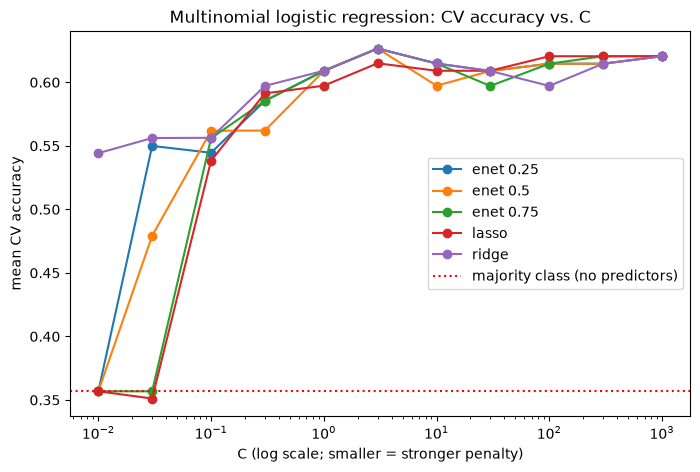

Highest CV accuracy: enet 0.75, C = 3.0, accuracy = 0.6266, log loss = 1.3052
Selected (1-SE) model: enet 0.75, C = 0.3, accuracy = 0.5854, log loss = 1.0912


,C,model,accuracy (mean),log loss (mean)
0,0.01,ridge,0.5442,1.2922
1,0.03,ridge,0.5561,1.1811
2,0.10,enet 0.5,0.5618,1.1935
3,0.30,ridge,0.5971,1.0374
4,1.00,enet 0.25,0.6091,1.0681
5,3.00,enet 0.75,0.6266,1.3052
6,10.00,enet 0.75,0.6148,1.7280
7,30.00,lasso,0.6091,2.2768
8,100.00,lasso,0.6205,2.3839
9,300.00,lasso,0.6205,2.4151


In [31]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, g in all_results.groupby("model"):
    ax.plot(g["C"], g["accuracy (mean)"], marker="o", label=name)
ax.axhline(acc_majority, color="red", ls=":", label="majority class (no predictors)")
ax.set(xscale="log", xlabel="C (log scale; smaller = stronger penalty)",
       ylabel="mean CV accuracy", title="Multinomial logistic regression: CV accuracy vs. C")
ax.legend()
plt.show()
 

best_acc = all_results.loc[all_results["accuracy (mean)"].idxmax()]
print(f"Highest CV accuracy: {best_acc['model']}, C = {best_acc['C']}, "
      f"accuracy = {best_acc['accuracy (mean)']:.4f}, log loss = {best_acc['log loss (mean)']:.4f}")
print(f"Selected (1-SE) model: {method_best}, C = {C_best}, "
      f"accuracy = {simplest['accuracy (mean)']:.4f}, log loss = {simplest['log loss (mean)']:.4f}")
 
all_results.loc[all_results.groupby("C")["accuracy (mean)"].idxmax(),
                ["C", "model", "accuracy (mean)", "log loss (mean)"]].round(4).reset_index(drop=True)

3b. Elastic net with C = 3 had the highest accuracy (0.6266) but a higher log loss (1.3052). The model from Part 3a (C = 0.3) had lower accuracy (0.5854) but a better log loss (1.0912). This shows that higher accuracy does not always mean better predictions. The first model predicts the correct class more often, while the second gives more reliable probabilities

In [32]:
large_C = all_results[all_results["C"] >= 10].pivot(index="C", columns="model", values="log loss (mean)")
print(f"Base-rate log loss: {ll_base:.4f}   |   unpenalized CV log loss: {unpen_scores['log loss (mean)']:.4f}")
below = large_C[large_C <= ll_base].stack().dropna()
print("C >= 10 models at or below the base rate:", "none" if below.empty else
      ", ".join(f"{m} at C = {c:g} ({v:.4f})" for (c, m), v in below.items()))
large_C.round(4)

Base-rate log loss: 1.5049   |   unpenalized CV log loss: 4.2544
C >= 10 models at or below the base rate: ridge at C = 10 (1.4655)


model,enet 0.25,enet 0.5,enet 0.75,lasso,ridge
C,,,,,
10.0,1.5326,1.6196,1.7280,1.9926,1.4655
30.0,1.9162,1.9975,2.0951,2.2768,1.8491
100.0,2.1718,2.2244,2.2926,2.3839,2.1293
300.0,2.3253,2.3559,2.3903,2.4151,2.2982
1000.0,2.4050,2.4118,2.4190,2.4267,2.3975


3c. As C increases, the penalty becomes weaker, causing the coefficients to grow larger and the model to make overly confident predictions. Because the predictors are highly related, this leads to more extreme mistakes and higher log loss. At C = 1000, log loss reaches about 2.4, which is worse than the baseline (1.5049). However, accuracy stays around 61–62% because the model still predicts the correct class most of the time. This shows that high accuracy does not always mean reliable predictions.

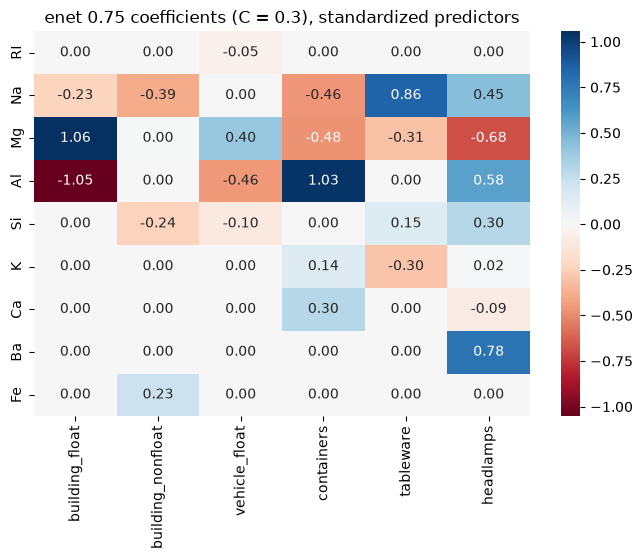

Number of classes with a nonzero coefficient, by feature:
RI    1
Na    5
Mg    6
Al    4
Si    4
K     3
Ca    2
Ba    1
Fe    1

Features nonzero for only one class:
  RI: vehicle_float (-0.052)
  Ba: headlamps (0.779)
  Fe: building_nonfloat (0.232)


In [33]:
model_best.fit(X_train, y_train)
coef_best = pd.DataFrame(model_best.named_steps["model"].coef_.T,
                         index=features, columns=label_names)
 
plt.figure(figsize=(8, 5))
sns.heatmap(coef_best, annot=True, fmt=".2f", cmap="RdBu", center=0)
plt.title(f"{method_best} coefficients (C = {C_best}), standardized predictors")
plt.show()
 

nonzero_per_feature = (coef_best != 0).sum(axis=1)
print("Number of classes with a nonzero coefficient, by feature:")
print(nonzero_per_feature.to_string())
one_class = nonzero_per_feature[nonzero_per_feature == 1].index
print("\nFeatures nonzero for only one class:")
for f in one_class:
    cls = coef_best.columns[coef_best.loc[f] != 0][0]
    print(f"  {f}: {cls} ({coef_best.loc[f, cls]:.3f})")

3d. The selected elastic net model (C = 0.3) has three features that affect only one class: RI (vehicle_float), Ba (headlamps), and Fe (building_nonfloat). Mg is the only feature with nonzero coefficients for all six classes. Compared to the unpenalized model, the coefficients are much smaller (−1.05 to 1.06) because regularization reduces their size and sets about half to zero.

In [34]:
def odds_factor(feature, a, b):
    diff = coef_best.loc[feature, a] - coef_best.loc[feature, b]
    return diff, np.exp(diff)
 
for feature, a, b in [("Ba", "headlamps", "building_float"), ("Mg", "building_float", "headlamps")]:
    diff, factor = odds_factor(feature, a, b)
    print(f"{feature}: odds of {a} vs. {b} multiplied by exp({coef_best.loc[feature, a]:.3f} - ({coef_best.loc[feature, b]:.3f})) "
          f"= exp({diff:.3f}) = {factor:.3f}")

Ba: odds of headlamps vs. building_float multiplied by exp(0.779 - (0.000)) = exp(0.779) = 2.180
Mg: odds of building_float vs. headlamps multiplied by exp(1.057 - (-0.679)) = exp(1.736) = 5.672


3e. A one SD increase in Ba increases the odds of headlamp glass compared to building_float by 2.18 times. A one SD increase in Mg increases the odds of building_float glass compared to headlamps by 5.67 times. This shows that higher Ba favors headlamps, while higher Mg favors building_float glass.

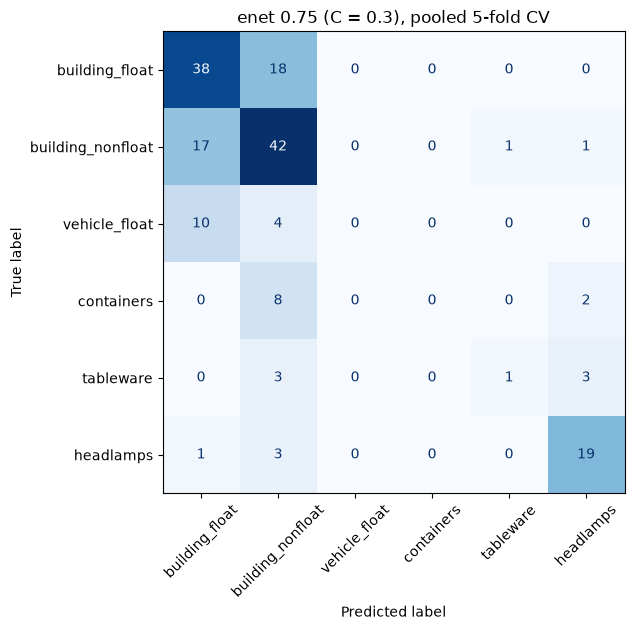

,vehicle_float fragments predicted as
building_float,10
building_nonfloat,4


In [36]:
pred_lr = cv_pred(model_best)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_train, pred_lr, labels=labels, display_labels=label_names,
                                        cmap="Blues", colorbar=False, ax=ax, xticks_rotation=45)
ax.set_title(f"{method_best} (C = {C_best}), pooled 5-fold CV")
plt.show()
 
pr_table = pd.DataFrame({
    "n (train)": y_train.value_counts().reindex(labels).values,
    "times predicted": pd.Series(pred_lr).value_counts().reindex(labels, fill_value=0).values,
    "precision": precision_score(y_train, pred_lr, labels=labels, average=None, zero_division=0),
    "recall": recall_score(y_train, pred_lr, labels=labels, average=None, zero_division=0),
}, index=label_names)
pr_table.round(3)
 

vf = pred_lr[y_train.values == 3]
pd.Series(vf).map(class_names).value_counts().rename("vehicle_float fragments predicted as").to_frame()

In [37]:
display(pr_table.round(3))

,n (train),times predicted,precision,recall
building_float,56,66,0.576,0.679
building_nonfloat,61,78,0.538,0.689
vehicle_float,14,0,0.000,0.000
containers,10,0,0.000,0.000
tableware,7,2,0.500,0.143
headlamps,23,25,0.760,0.826


4a. The selected model performs well on common glass types and headlamps but struggles with rare classes. Headlamps has the highest recall (0.826) and precision (0.760). The two building glass classes have recall around 0.68–0.69 and are often confused with each other  with 18 mistakes in one direction and 17 in the other.

4b.  Most vehicle_float fragments (10 of 14) are incorrectly classified as building_float, while the other 4 are classified as building_nonfloat. This happens because both types have similar chemical compositions. Since building_float has more training examples (56 vs. 14), the model is more likely to predict that class when unsure.

## Part 3 


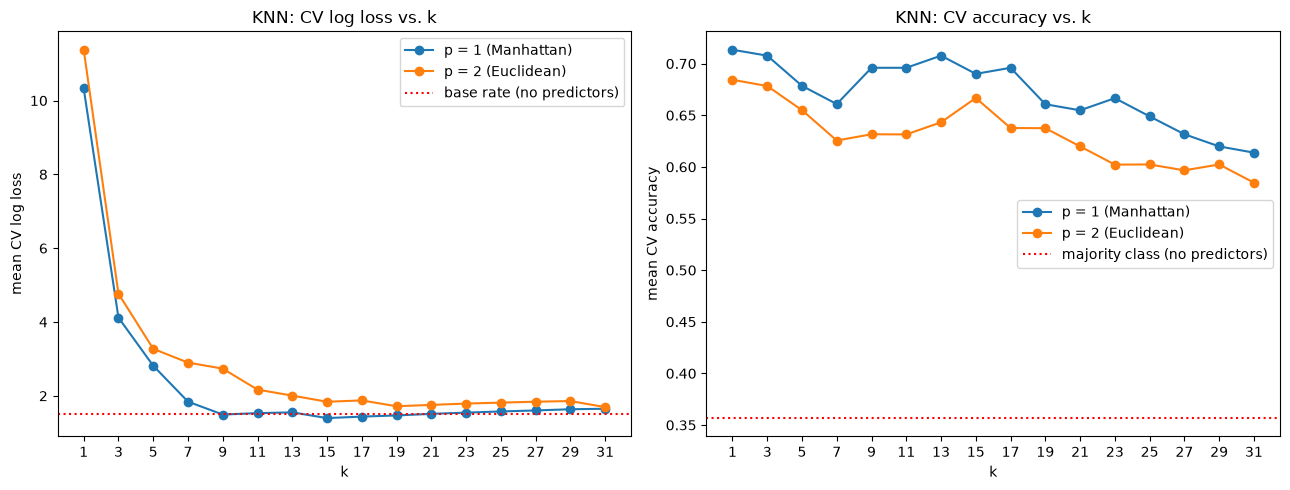

In [ ]:
def make_knn(k, p=2):
    return Pipeline(steps=[
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=k, p=p)),
    ])
 
k_values = range(1, 32, 2)   
knn_results = pd.DataFrame([{"k": k, "p": p, **cv_scores(make_knn(k, p))}
                            for p in [1, 2] for k in k_values])
 

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
p_labels = {1: "p = 1 (Manhattan)", 2: "p = 2 (Euclidean)"}
for p, g in knn_results.groupby("p"):
    axes[0].plot(g["k"], g["log loss (mean)"], marker="o", label=p_labels[p])
    axes[1].plot(g["k"], g["accuracy (mean)"], marker="o", label=p_labels[p])
axes[0].axhline(ll_base, color="red", ls=":", label="base rate (no predictors)")
axes[1].axhline(acc_majority, color="red", ls=":", label="majority class (no predictors)")
axes[0].set(xlabel="k", ylabel="mean CV log loss", title="KNN: CV log loss vs. k")
axes[1].set(xlabel="k", ylabel="mean CV accuracy", title="KNN: CV accuracy vs. k")
for ax in axes:
    ax.set_xticks(list(k_values))
    ax.legend()
plt.tight_layout()
plt.show()

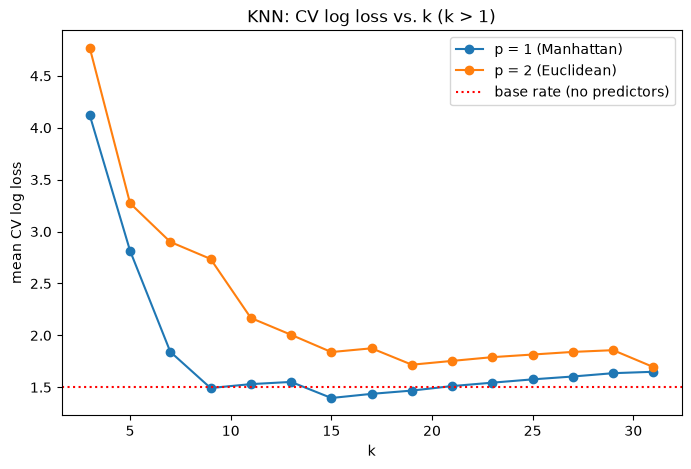

Lowest CV log loss:   k = 15, p = 1 (log loss = 1.3967, accuracy = 0.6901)
Highest CV accuracy:  k = 1, p = 1 (log loss = 10.3285, accuracy = 0.7134)
Largest CV log loss in the grid: 11.3765


,k,p,log loss (mean),log loss (sd),accuracy (mean),accuracy (sd)
0,1,1,10.3285,1.9404,0.7134,0.0538
6,13,1,1.5517,0.7257,0.7077,0.0517
1,3,1,4.1196,1.0725,0.7077,0.0826
8,17,1,1.4366,0.4685,0.6960,0.0601
5,11,1,1.5303,0.7222,0.6960,0.0682
4,9,1,1.4928,0.7274,0.6960,0.0629


In [39]:
fig, ax = plt.subplots(figsize=(8, 5))
for p, g in knn_results[knn_results["k"] > 1].groupby("p"):
    ax.plot(g["k"], g["log loss (mean)"], marker="o", label=p_labels[p])
ax.axhline(ll_base, color="red", ls=":", label="base rate (no predictors)")
ax.set(xlabel="k", ylabel="mean CV log loss", title="KNN: CV log loss vs. k (k > 1)")
ax.legend()
plt.show()
 
best_ll = knn_results.loc[knn_results["log loss (mean)"].idxmin()]
best_acc_knn = knn_results.loc[knn_results["accuracy (mean)"].idxmax()]
print(f"Lowest CV log loss:   k = {int(best_ll['k'])}, p = {int(best_ll['p'])} "
      f"(log loss = {best_ll['log loss (mean)']:.4f}, accuracy = {best_ll['accuracy (mean)']:.4f})")
print(f"Highest CV accuracy:  k = {int(best_acc_knn['k'])}, p = {int(best_acc_knn['p'])} "
      f"(log loss = {best_acc_knn['log loss (mean)']:.4f}, accuracy = {best_acc_knn['accuracy (mean)']:.4f})")
print(f"Largest CV log loss in the grid: {knn_results['log loss (mean)'].max():.4f}")
knn_results.sort_values("accuracy (mean)", ascending=False).head(6).round(4)

In [40]:
k_best, p_best = int(best_ll["k"]), int(best_ll["p"])
model_knn = make_knn(k_best, p_best)
print(f"Selected KNN: k = {k_best}, p = {p_best}")

Selected KNN: k = 15, p = 1


 I compared KNN models using Manhattan and Euclidean distances with k values from 1 to 31. Manhattan performed better overall, with lower log loss and higher accuracy. Log loss was highest at small k values, improved around k = 9–15, then slowly increased. Accuracy was highest at smaller k values and gradually decreased as k increased.

1a. The best KNN model uses k = 15 and Manhattan distance (p = 1), with a log loss of 1.3967 and accuracy of 0.6901. Its log loss is better than the baseline (1.5049). 

1b. If I chose based on accuracy, I would select k = 1, p = 1, which has the highest accuracy (0.7134) but a very high log loss (10.3285). This happens because the model uses only one neighbor and makes 100% confident predictions, even when its wrong. This leads to large errors and possible overfitting. I would choose k = 15 instead because it has a much lower log loss (1.3967) and still maintains good accuracy (0.6901), making its probabilities more reliable

In [41]:
proba_knn = cross_val_predict(model_knn, X_train, y_train, cv=cv, method="predict_proba")
true_idx = np.searchsorted(labels, y_train.values)          
p_true_knn = proba_knn[np.arange(len(y_train)), true_idx]
 
zero = p_true_knn == 0
print(f"Fragments with P(true class) exactly 0: {zero.sum()} of {len(y_train)}")
y_train[zero].map(class_names).value_counts().rename("count").to_frame()

Fragments with P(true class) exactly 0: 3 of 171


,count
type,
headlamps,2
containers,1


2a. Out of 171 fragments, 3 had a probability of 0 for their correct class (2 headlamps and 1 container). This happened because none of their 15 nearest neighbors were from the same class, suggesting these fragments are unusual.

In [42]:
eps = np.finfo(float).eps
n = len(y_train)
loss_i = -np.log(np.clip(p_true_knn, eps, 1))   
 
pooled_ll = loss_i.mean()
print(f"Pooled out-of-fold KNN log loss (by hand): {pooled_ll:.4f}")
print(f"Pooled out-of-fold KNN log loss (sklearn): {log_loss(y_train, proba_knn, labels=labels):.4f}")
print(f"(The mean of the 5 per-fold log losses from Q1 was {best_ll['log loss (mean)']:.4f}.)\n")
 
print(f"Each zero-probability fragment: -ln(eps) = {-np.log(eps):.4f}")
print(f"  ...which adds -ln(eps)/n = {-np.log(eps):.4f}/{n} = {-np.log(eps)/n:.4f} to the mean log loss")
share = loss_i[zero].sum() / loss_i.sum()
print(f"Total contribution of the {zero.sum()} zero-probability fragments to the mean: {loss_i[zero].sum()/n:.4f}")
print(f"Percentage of total KNN log loss from these fragments: {share:.1%}")
print(f"Mean log loss of the remaining {(~zero).sum()} fragments: {loss_i[~zero].mean():.4f}")

Pooled out-of-fold KNN log loss (by hand): 1.3991
Pooled out-of-fold KNN log loss (sklearn): 1.3991
(The mean of the 5 per-fold log losses from Q1 was 1.3967.)

Each zero-probability fragment: -ln(eps) = 36.0437
  ...which adds -ln(eps)/n = 36.0437/171 = 0.2108 to the mean log loss
Total contribution of the 3 zero-probability fragments to the mean: 0.6323
Percentage of total KNN log loss from these fragments: 45.2%
Mean log loss of the remaining 168 fragments: 0.7804


2b. The 3 fragments with zero probability caused 45.2% of the total log loss. Without them, log loss would drop to 0.7804. This shows that KNN performs well overall, but a few very bad predictions greatly increase its log loss

In [45]:
lr_name = f"Logistic: {method_best} (C = {C_best})"
knn_name = f"KNN (k = {k_best}, p = {p_best})"
 
comparison = pd.DataFrame({
    lr_name: cv_scores(model_best),
    knn_name: cv_scores(model_knn),
}).T
comparison.round(4)
display(comparison.round(4))
 

pred_knn = cv_pred(model_knn)
recall_table = pd.DataFrame({
    "n (train)": y_train.value_counts().reindex(labels).values,
    lr_name: recall_score(y_train, pred_lr, labels=labels, average=None, zero_division=0),
    knn_name: recall_score(y_train, pred_knn, labels=labels, average=None, zero_division=0),
}, index=label_names)
recall_table["KNN - logistic"] = recall_table[knn_name] - recall_table[lr_name]
recall_table.round(3)

,log loss (mean),log loss (sd),accuracy (mean),accuracy (sd)
Logistic: enet 0.75 (C = 0.3),1.0912,0.1711,0.5854,0.0575
"KNN (k = 15, p = 1)",1.3967,0.4744,0.6901,0.0437


,n (train),Logistic: enet 0.75 (C = 0.3),"KNN (k = 15, p = 1)",KNN - logistic
building_float,56,0.679,0.964,0.286
building_nonfloat,61,0.689,0.721,0.033
vehicle_float,14,0.000,0.000,0.000
containers,10,0.000,0.200,0.200
tableware,7,0.143,0.000,-0.143
headlamps,23,0.826,0.783,-0.043


3a. Logistic regression has a better log loss (1.0912 vs. 1.3967), while KNN has higher accuracy (69.0% vs. 58.5%). KNN performs better on building glass and containers, while logistic regression performs better on headlamps and tableware. Neither model correctly predicts vehicle_float glass.

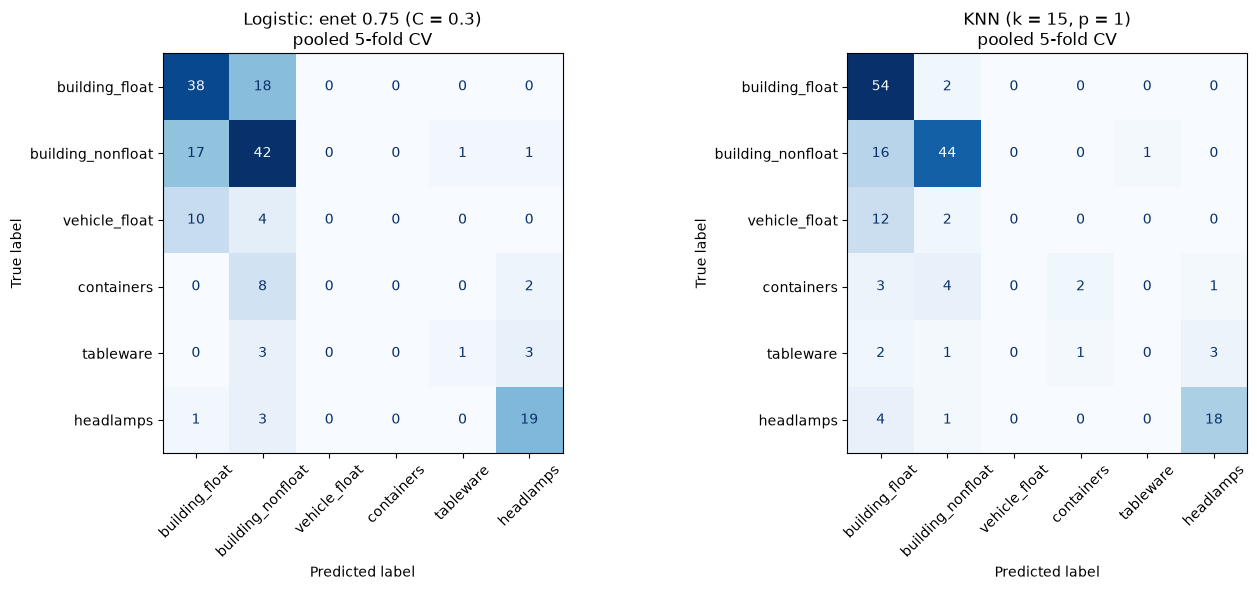

Out-of-fold accuracy: logistic = 0.5848, KNN = 0.6901


,correct (logistic),correct (KNN),KNN - logistic
building_float,38,54,16
building_nonfloat,42,44,2
vehicle_float,0,0,0
containers,0,2,2
tableware,1,0,-1
headlamps,19,18,-1
Total,100,118,18


In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, pred) in zip(axes, [(lr_name, pred_lr), (knn_name, pred_knn)]):
    ConfusionMatrixDisplay.from_predictions(y_train, pred, labels=labels, display_labels=label_names,
                                            cmap="Blues", colorbar=False, ax=ax, xticks_rotation=45)
    ax.set_title(f"{name}\npooled 5-fold CV")
plt.tight_layout()
plt.show()

cm_lr = confusion_matrix(y_train, pred_lr, labels=labels)
cm_knn = confusion_matrix(y_train, pred_knn, labels=labels)
diff = pd.DataFrame({
    "correct (logistic)": np.diag(cm_lr),
    "correct (KNN)": np.diag(cm_knn),
}, index=label_names)
diff["KNN - logistic"] = diff["correct (KNN)"] - diff["correct (logistic)"]
diff.loc["Total"] = diff.sum()
print(f"Out-of-fold accuracy: logistic = {np.trace(cm_lr)/n:.4f}, KNN = {np.trace(cm_knn)/n:.4f}")
diff

3b. KNN correctly predicts 118 fragments, compared to 100 for logistic regression. Most of KNN's 18 extra correct predictions come from building_float (16). However, KNN predicts building_float too often, causing mistakes with other classes. Although KNN has higher accuracy, its log loss is worse (1.3967 vs. 1.0912), and it struggles with rare classes. Therefore, logistic regression is the better choice because it provides more reliable probabilities

3c. KNN performs better on building glass and containers, while logistic regression performs better on headlamps and tableware. KNN can find more complex patterns, while logistic regression uses straight boundaries. Both models struggle with rare glass types because there are fewer examples and the types are very similar.

,test log loss,test accuracy,CV log loss,CV accuracy
Logistic: enet 0.75 (C = 0.3),0.8864,0.6512,1.0912,0.5854
"KNN (k = 15, p = 1)",0.7538,0.6279,1.3967,0.6901


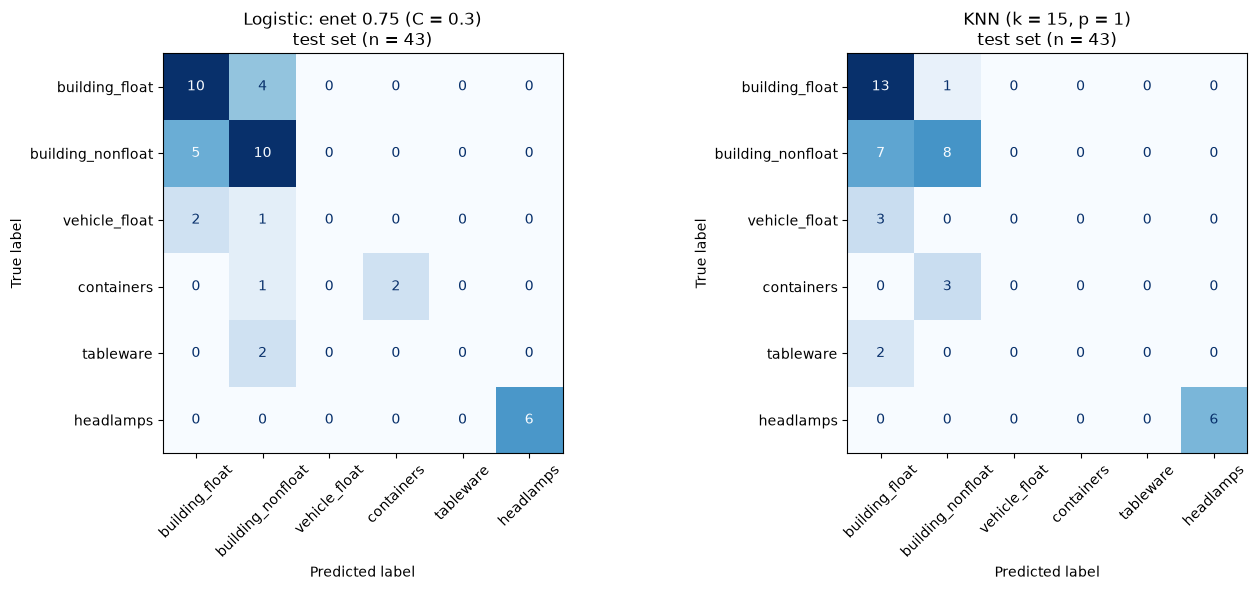

In [48]:
model_best.fit(X_train, y_train)
model_knn.fit(X_train, y_train)
 
test_results = pd.DataFrame({
    name: {
        "test log loss": log_loss(y_test, m.predict_proba(X_test), labels=labels),
        "test accuracy": accuracy_score(y_test, m.predict(X_test)),
    }
    for name, m in [(lr_name, model_best), (knn_name, model_knn)]
}).T
test_results["CV log loss"] = comparison["log loss (mean)"]
test_results["CV accuracy"] = comparison["accuracy (mean)"]
display(test_results.round(4))
 

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, m) in zip(axes, [(lr_name, model_best), (knn_name, model_knn)]):
    ConfusionMatrixDisplay.from_predictions(y_test, m.predict(X_test), labels=labels, display_labels=label_names,
                                            cmap="Blues", colorbar=False, ax=ax, xticks_rotation=45)
    ax.set_title(f"{name}\ntest set (n = {len(y_test)})")
plt.tight_layout()
plt.show()

In [51]:
display(pd.DataFrame({
    "n (test)": y_test.value_counts().reindex(labels).values,
    f"recall: {lr_name}": recall_score(y_test, model_best.predict(X_test), labels=labels, average=None, zero_division=0),
    f"recall: {knn_name}": recall_score(y_test, model_knn.predict(X_test), labels=labels, average=None, zero_division=0),
}, index=label_names).round(3))

 

proba_knn_test = model_knn.predict_proba(X_test)
p_true_test = proba_knn_test[np.arange(len(y_test)), np.searchsorted(labels, y_test.values)]
n_test = len(y_test)
print(f"KNN test fragments with P(true class) = 0: {(p_true_test == 0).sum()}")
print(f"One fragment with probability 0 adds -ln(eps)/n_test = {-np.log(eps):.4f}/{n_test} "
      f"= {-np.log(eps)/n_test:.4f} to KNN's test log loss")

,n (test),recall: Logistic: enet 0.75 (C = 0.3),"recall: KNN (k = 15, p = 1)"
building_float,14,0.714,0.929
building_nonfloat,15,0.667,0.533
vehicle_float,3,0.000,0.000
containers,3,0.667,0.000
tableware,2,0.000,0.000
headlamps,6,1.000,1.000


KNN test fragments with P(true class) = 0: 0
One fragment with probability 0 adds -ln(eps)/n_test = 36.0437/43 = 0.8382 to KNN's test log loss


4a. No, the test results were opposite from CV. On the test set, KNN had better log loss (0.7538 vs. 0.8864), while logistic regression had slightly higher accuracy (65.1% vs. 62.8%). This happened because KNN had no zero-probability errors on the test set. This shows that results can vary with small datasets.

4b. The test set has only 43 fragments, making the results less reliable. Both models struggle with rare glass types but correctly predict all 6 headlamps. We cannot confidently say which model is better. Just one zero-probability error could increase KNN's log loss from 0.7538 to 1.59. This shows how small datasets can affect results.